# Predicting NYC Yellow Taxi Fares
**Group 4** | PhDAI 733 M21 | University of Cumberlands

**Problem:** Predict the fare of a yellow taxi trip from its distance, trip time, hour and day type.

**Data:** official NYC TLC yellow taxi records, September 2026.

**Score:** average error in dollars (lower is better).

**Steps:** 1 Setup, 2 Load, 3 Clean, 4 Prepare, 5 Explore, 6 Split, 7 Train, 8 Tune, 9 Check where the model is less accurate.

## 1. Setup
Import the Python libraries we use: pandas and NumPy for data, Matplotlib and Seaborn for charts, scikit-learn for modeling.

In [1]:
# Ignore warning messages so the output stays clean
import warnings; warnings.filterwarnings('ignore')
# pandas and NumPy: tables and numbers
import pandas as pd, numpy as np
# Matplotlib and Seaborn: charts
import matplotlib.pyplot as plt, seaborn as sns
# scikit-learn: split the data, tune settings, build pipelines
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
# The two model types we compare, and the scores we use
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
# Use a clean chart style
sns.set_theme(style='whitegrid')

## 2. Load the official data
Source: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page.
The file is read from Google Drive. We load only four columns: pick-up time, drop-off time, trip distance and fare.

In [6]:
# Connect Google Drive so Colab can read the data file saved there
from google.colab import drive
drive.mount('/content/drive')

# Location of the official TLC parquet file in the team's Drive folder
file_path = "/content/drive/MyDrive/NYC_Taxi_AI_Project/yellow_tripdata_2026-09.parquet"


# Read only the four columns we need (faster and uses less memory)
raw = pd.read_parquet(file_path, columns=['tpep_pickup_datetime','tpep_dropoff_datetime','trip_distance','fare_amount'])

# Show the size (rows, columns) and a first summary of the raw data
print(raw.shape)
raw.describe().round(1)

Mounted at /content/drive
(3876044, 4)


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,fare_amount
count,3876044,3876044,3876044.0,3876044.0
mean,2026-09-16 12:39:30.448868,2026-09-16 12:58:15.609074,5.0,23.1
min,2009-01-01 09:32:44,2009-01-01 10:22:44,0.0,-1800.0
25%,2026-09-09 18:19:06.750000,2026-09-09 18:39:43.750000,1.1,10.7
50%,2026-09-16 18:08:17,2026-09-16 18:27:43.500000,2.0,17.7
75%,2026-09-23 20:21:52.250000,2026-09-23 20:39:48.250000,4.2,29.2
max,2026-10-07 07:40:40,2026-10-07 07:59:16,232644.8,9999.7
std,NaN,NaN,463.4,20.2


## 3. Clean
The raw file has impossible trips (a 2009 pick-up, a 232,645-mile trip, fares from -$1,800 to $9,999). We remove trips that break four simple rules and count what each rule removes.

In [7]:
# Work on a copy so the raw data stays untouched
df = raw.copy()
# Trip time in minutes = drop-off time minus pick-up time
df['minutes'] = (df.tpep_dropoff_datetime - df.tpep_pickup_datetime).dt.total_seconds() / 60
# Keep a list of how many trips each rule removes
steps = []
# Helper: keep only trips that pass a rule, and record how many were removed
def keep(name, mask):
    global df
    before = len(df); df = df[mask(df)].copy(); steps.append((name, before - len(df)))
# Rule 1: pick-up must be in September 2026
keep('Pick-up not in September 2026', lambda d: (d.tpep_pickup_datetime >= '2026-09-01') & (d.tpep_pickup_datetime < '2026-10-01'))
# Rule 2: realistic distance (0.1 to 100 miles)
keep('Distance not between 0.1 and 100 miles', lambda d: d.trip_distance.between(0.1, 100))
# Rule 3: realistic duration (1 to 180 minutes)
keep('Duration not between 1 and 180 minutes', lambda d: d.minutes.between(1, 180))
# Rule 4: realistic fare ($3 to $500)
keep('Fare below $3 or above $500', lambda d: d.fare_amount.between(3, 500))
# Report how many trips each rule removed, and how many remain
for name, n in steps: print(f'{n:>9,}  {name}')
print(f'Kept {len(df):,} of {len(raw):,} trips ({len(df)/len(raw):.1%})')

       22  Pick-up not in September 2026
  178,826  Distance not between 0.1 and 100 miles
   50,717  Duration not between 1 and 180 minutes
   13,440  Fare below $3 or above $500
Kept 3,633,039 of 3,876,044 trips (93.7%)


## 4. Prepare
We use a random 100,000 trips to keep things fast. Inputs: distance, trip minutes, hour and weekend. We leave out tip, tolls and total because they include or follow the fare, which would give away the answer.

In [8]:
# Take a random sample of 100,000 trips (fixed seed 42 so everyone gets the same sample)
df = df.sample(n=100000, random_state=42).reset_index(drop=True)
# New input: hour of day the trip started (0 to 23)
df['hour'] = df.tpep_pickup_datetime.dt.hour
# New input: 1 if the trip started on Saturday or Sunday, otherwise 0
df['weekend'] = (df.tpep_pickup_datetime.dt.dayofweek >= 5).astype(int)
# The four inputs the models will use
features = ['trip_distance', 'minutes', 'hour', 'weekend']
# First look at the fare: average vs median, and how strongly distance and time relate to it
print('Average fare $%.2f, median $%.2f' % (df.fare_amount.mean(), df.fare_amount.median()))
print('Correlation with fare: distance %.2f, minutes %.2f' % (df.trip_distance.corr(df.fare_amount), df.minutes.corr(df.fare_amount)))

Average fare $22.99, median $17.21
Correlation with fare: distance 0.88, minutes 0.82


## 5. Explore the data
Before modeling, we look at the data to understand it: summary numbers, how the columns are spread, how they relate to the fare, and patterns by hour and day.

### 5.1 Summary statistics

In [ ]:
# Summary statistics of the cleaned sample: count, average, spread and range for each column
df[['fare_amount', 'trip_distance', 'minutes']].describe().round(2)

,fare_amount,trip_distance,minutes
count,100000.00,100000.00,100000.00
mean,22.99,3.73,18.88
std,18.38,4.39,13.68
min,3.00,0.10,1.00
25%,10.70,1.18,9.50
50%,17.21,2.10,15.62
75%,28.90,4.42,24.23
max,444.70,95.54,170.25


**What we see:** the average fare ($22.99) is higher than the median ($17.21), so fares are right-skewed: most trips are cheap and a few very expensive ones pull the average up (the largest fare is $444.70). The typical trip is about 2.1 miles and 15.6 minutes.

### 5.2 Fare and distance

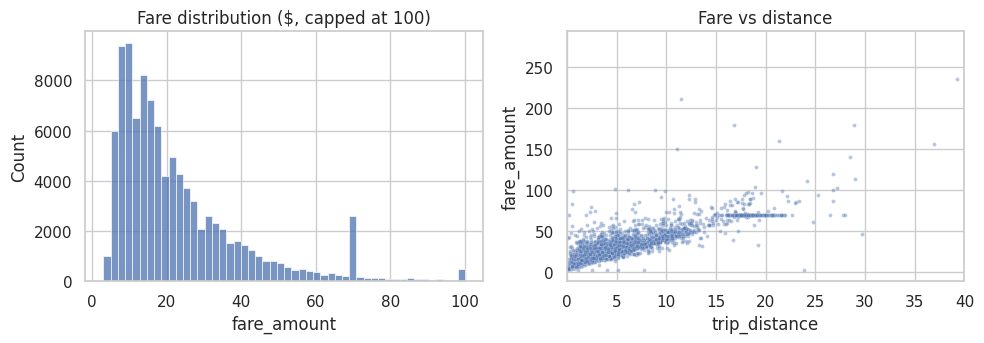

In [9]:
# Left: how fares are spread. Right: how fare changes with distance (5,000 random trips)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
# Histogram of fares (capped at $100 so a few very large fares do not stretch the chart)
sns.histplot(df.fare_amount.clip(upper=100), bins=50, ax=ax[0]); ax[0].set_title('Fare distribution ($, capped at 100)')
# Scatter plot of fare against distance
sns.scatterplot(data=df.sample(5000, random_state=1), x='trip_distance', y='fare_amount', s=8, alpha=0.4, ax=ax[1])
ax[1].set_xlim(0, 40); ax[1].set_title('Fare vs distance')
plt.tight_layout(); plt.show()

**What we see:** about 76% of fares are under $30, and fare rises roughly in a straight line as distance grows, which is why a simple linear model is a good start.

### 5.3 Distance and trip time

Median trip: 2.1 miles, 15.6 minutes
Share of trips under 3 miles: 63%


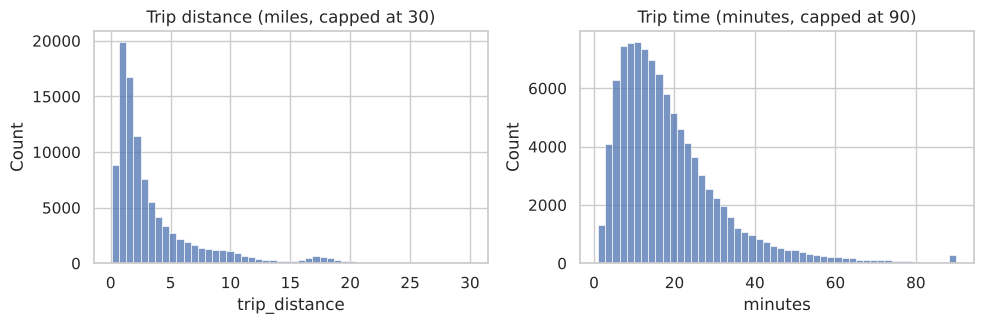

In [ ]:
# Distributions of trip distance and trip time (values are capped so the long tail does not squash the chart)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
sns.histplot(df.trip_distance.clip(upper=30), bins=50, ax=ax[0]); ax[0].set_title('Trip distance (miles, capped at 30)')
sns.histplot(df.minutes.clip(upper=90), bins=50, ax=ax[1]); ax[1].set_title('Trip time (minutes, capped at 90)')
plt.tight_layout(); plt.show()
print('Median trip: %.1f miles, %.1f minutes' % (df.trip_distance.median(), df.minutes.median()))
print('Share of trips under 3 miles: %.0f%%' % (100 * (df.trip_distance < 3).mean()))

**What we see:** most trips are short: 63% are under 3 miles, and only about 2% last longer than an hour.

### 5.4 How each column relates to the fare

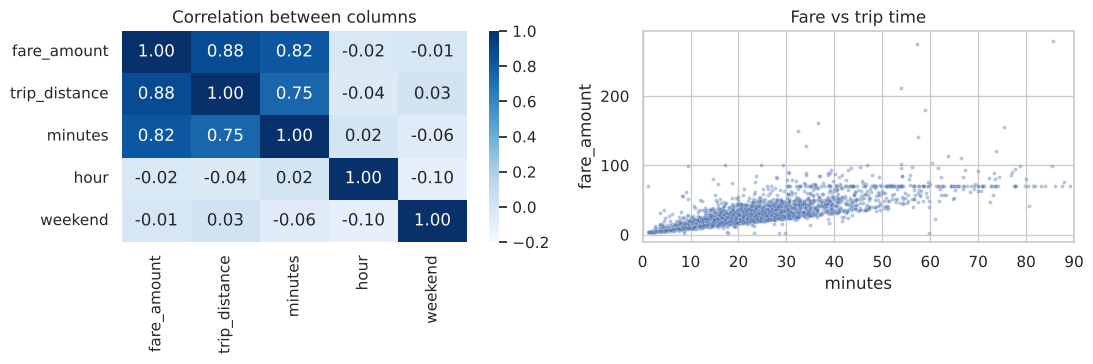

In [ ]:
# Relationships: how strongly each column moves together with the fare (1 = perfectly, 0 = not at all)
cols = ['fare_amount', 'trip_distance', 'minutes', 'hour', 'weekend']
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='Blues', vmin=-0.2, vmax=1, ax=ax[0]); ax[0].set_title('Correlation between columns')
sns.scatterplot(data=df.sample(5000, random_state=1), x='minutes', y='fare_amount', s=8, alpha=0.4, ax=ax[1])
ax[1].set_xlim(0, 90); ax[1].set_title('Fare vs trip time')
plt.tight_layout(); plt.show()

**What we see:** distance (0.88) and trip time (0.82) are strongly related to the fare. They are also related to each other (0.75), because longer trips take longer. In the fare vs trip time chart, a flat line of fares near $70 appears regardless of time, which looks like fixed-price trips (we did not check). Pick-up hour (-0.02) and weekend (-0.01) show almost no straight-line relationship with the fare.

### 5.5 Patterns by hour and day

Busiest hour: 21:00 | Highest average fare: 4:00 ($29.54) | Lowest: 18:00 ($20.11)
         count   mean  median
weekend                      
weekday  72243  23.05    17.0
weekend  27757  22.82    17.7


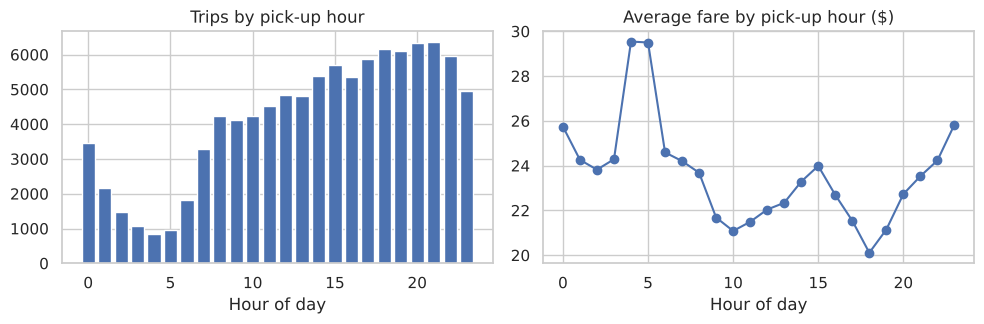

In [ ]:
# Patterns over time: trips and average fare by pick-up hour, and weekday vs weekend
by_hour = df.groupby('hour').agg(trips=('fare_amount', 'size'), avg_fare=('fare_amount', 'mean'))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(by_hour.index, by_hour.trips); ax[0].set_title('Trips by pick-up hour'); ax[0].set_xlabel('Hour of day')
ax[1].plot(by_hour.index, by_hour.avg_fare, marker='o'); ax[1].set_title('Average fare by pick-up hour ($)'); ax[1].set_xlabel('Hour of day')
plt.tight_layout(); plt.show()
print('Busiest hour: %d:00 | Highest average fare: %d:00 ($%.2f) | Lowest: %d:00 ($%.2f)' % (by_hour.trips.idxmax(), by_hour.avg_fare.idxmax(), by_hour.avg_fare.max(), by_hour.avg_fare.idxmin(), by_hour.avg_fare.min()))
print(df.groupby('weekend').fare_amount.agg(['count', 'mean', 'median']).rename(index={0: 'weekday', 1: 'weekend'}).round(2))

**What we see:** the busiest hour is 9 pm. The highest average fare is at 4 am ($29.54) and the lowest at 6 pm ($20.11). Weekday and weekend fares are almost the same on average ($23.05 vs $22.82). We did not test why fares differ by hour.

## 6. Split: learn on 80%, test on 20%
The model learns from 80% of the trips. We test it on the other 20%, which it has never seen, to get an honest score.

In [10]:
# X = the inputs, y = the fare we want to predict
X, y = df[features], df.fare_amount
# 80% of trips to learn from, 20% kept hidden to test (seed 42 = same split every time)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), 'train trips,', len(X_test), 'test trips')
# Helper: print the average error in dollars (MAE) and R2 for a set of predictions
def score(name, pred):
    print(f'{name:34s} average error ${mean_absolute_error(y_test, pred):.2f} | R2 {r2_score(y_test, pred):.3f}')

80000 train trips, 20000 test trips


## 7. Train models, simple to detailed
We start with the simplest guess and add detail step by step, so we can see what each addition gains.

In [11]:
# Baseline: predict the average training fare for every test trip
score('Guess the average fare', np.full(len(y_test), y_train.mean()))
# Model 1: a straight line from distance to fare (scaling happens inside the pipeline)
m1 = Pipeline([('scale', StandardScaler()), ('model', LinearRegression())]).fit(X_train[['trip_distance']], y_train)
score('Linear regression, distance only', m1.predict(X_test[['trip_distance']]))
# Convert the learned slope back to dollars per mile
print('   each extra mile adds about $%.2f' % (m1.named_steps['model'].coef_[0] / m1.named_steps['scale'].scale_[0]))
# Model 2: the same kind of line, now using all four inputs
m2 = Pipeline([('scale', StandardScaler()), ('model', LinearRegression())]).fit(X_train, y_train)
score('Linear regression, all 4 features', m2.predict(X_test))
# Model 3: random forest, many decision trees that vote (100 trees)
m3 = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train, y_train)
score('Random forest', m3.predict(X_test))

Guess the average fare             average error $12.93 | R2 -0.000
Linear regression, distance only   average error $5.28 | R2 0.787
   each extra mile adds about $3.64
Linear regression, all 4 features  average error $3.52 | R2 0.839
Random forest                      average error $3.44 | R2 0.838


## 8. Tune the random forest
Grid search tries a few settings (tree depth and leaf size) with 3-fold cross-validation on 20,000 training trips, then refits on all training trips.

In [12]:
# Use 20,000 training trips for the search so it runs quickly
small = X_train.index[:20000]
# Grid search: try each combination of tree depth and minimum leaf size, scored by average error with 3-fold cross-validation
grid = GridSearchCV(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    {'max_depth': [5, 10, None], 'min_samples_leaf': [1, 5]},
    cv=3, scoring='neg_mean_absolute_error').fit(X_train.loc[small], y_train.loc[small])
print('Best settings:', grid.best_params_)
# Refit the forest with the best settings on all 80,000 training trips
best = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, **grid.best_params_).fit(X_train, y_train)
# Predict the hidden test trips and score them
pred = best.predict(X_test)
score('Random forest, tuned', pred)

Best settings: {'max_depth': 10, 'min_samples_leaf': 5}
Random forest, tuned               average error $3.18 | R2 0.855


Predicted vs actual fares for the tuned model:

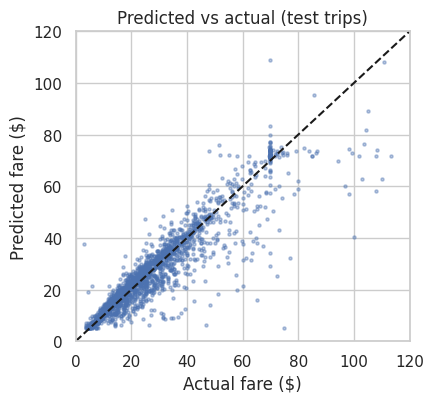

In [13]:
# Plot predicted vs actual fare for 3,000 test trips; points near the dashed line are good predictions
plt.figure(figsize=(4.5, 4.2))
plt.scatter(y_test[:3000], pred[:3000], s=5, alpha=0.4)
# Dashed line = perfect prediction
plt.plot([0, 120], [0, 120], 'k--'); plt.xlim(0, 120); plt.ylim(0, 120)
plt.xlabel('Actual fare ($)'); plt.ylabel('Predicted fare ($)'); plt.title('Predicted vs actual (test trips)')
plt.tight_layout(); plt.show()

## 9. Where is the model less accurate?
The average error hides differences between kinds of trips. We compare the error by trip length and by time of day.

In [14]:
# Collect the test trips with their actual fare and the model's error in dollars
te = X_test.copy(); te['fare'] = y_test; te['error'] = np.abs(pred - y_test)
# Group trips by length
te['trip length'] = pd.cut(te.trip_distance, [0, 2, 5, 10, 100], labels=['under 2 mi', '2-5 mi', '5-10 mi', 'over 10 mi'])
# Group trips by time of day: night, evening rush, or other hours
te['time of day'] = np.where((te.hour >= 22) | (te.hour < 5), 'night (10pm-5am)', np.where(te.hour.between(16, 19), 'evening rush (4-8pm)', 'other hours'))
# For each group show number of trips, average fare and average error
for col in ['trip length', 'time of day']:
    print(te.groupby(col).agg(trips=('fare', 'size'), avg_fare=('fare', 'mean'), avg_error=('error', 'mean')).round(2), '\n')

             trips  avg_fare  avg_error
trip length                            
under 2 mi    9719     11.86       1.64
2-5 mi        5970     22.98       3.62
5-10 mi       2701     37.30       5.15
over 10 mi    1610     64.96       7.47 

                      trips  avg_fare  avg_error
time of day                                     
evening rush (4-8pm)   4677     21.41       2.24
night (10pm-5am)       4062     24.76       4.51
other hours           11261     22.83       3.08 



## Ethics and limits
- One month of data and a 100,000-trip sample.
- Errors in dollars are larger for long trips and night trips.
- Trip time is only known after the ride, so a real upfront quote would use distance or predicted time.
- Use as an estimate only. Never use it to refuse rides or price riders differently by area. Pick-up and drop-off places are sensitive, so keep them private.